In [ ]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

df = pd.read_csv("painting_dataset_cleaned.csv")

print("Original dataset shape:", df.shape)

df["sub_category"] = df["sub_category"].astype("string").str.strip()
df = df[
    df["sub_category"].str.casefold() == "painting"
].copy()

features = [
    "item_name",
    "quantity",
    "building_type",
    "city",
    "state",
    "project_start_date"
]

target = "amount_inr"

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

df[target] = pd.to_numeric(
    df[target], errors="coerce"
)

df["project_start_date"] = pd.to_datetime(
    df["project_start_date"], errors="coerce"
)

required_cols = features + [target, "project_id"]

df = df.dropna(subset=required_cols).copy()
df = df[
    (df[target] >= 0) &
    (df["quantity"] >= 0)
].copy()

print("Filtered dataset shape:", df.shape)
print("Unique projects:", df["project_id"].nunique())

X = df[features].copy()
y = df[target].copy()
groups = df["project_id"].copy()

X["project_year"] = X["project_start_date"].dt.year
X["project_month"] = X["project_start_date"].dt.month

X = X.drop(columns=["project_start_date"])

print("\nFeatures used:")
print(X.columns.tolist())

print("\nTarget:", target)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Actual training proportion:",
    round(len(X_train) / len(X) * 100, 2), "%"
)

print(
    "Actual testing proportion:",
    round(len(X_test) / len(X) * 100, 2), "%"
)

assert set(groups_train).isdisjoint(set(groups_test))

print("Project overlap between train and test: None")

n_groups = groups_train.nunique()

if n_groups >= 5:
    cv = GroupKFold(n_splits=5)

    print("\nUsing 5-fold GroupKFold cross-validation.")

    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_train, y_train, groups=groups_train),
        start=1
    ):
        print(
            f"Fold {fold}: "
            f"Train={len(tr_idx)}, "
            f"Validation={len(val_idx)}, "
            f"Validation projects="
            f"{groups_train.iloc[val_idx].nunique()}"
        )

else:
    cv = None
    print(
        "\nNot enough distinct training projects for "
        "5-fold cross-validation. Use fewer folds."
    )

X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_csv("y_train.csv", index=False, header=[target])
y_test.to_csv("y_test.csv", index=False, header=[target])

groups_train.to_csv("groups_train.csv", index=False, header=["project_id"])
groups_test.to_csv("groups_test.csv", index=False, header=["project_id"])

print("\nSaved:")
print("X_train.csv")
print("X_test.csv")
print("y_train.csv")
print("y_test.csv")
print("groups_train.csv")
print("groups_test.csv")

Original dataset shape: (1199, 21)
Filtered dataset shape: (1199, 21)
Unique projects: 745

Features used:
['item_name', 'quantity', 'building_type', 'city', 'state', 'project_year', 'project_month']

Target: amount_inr

Training samples: 846
Testing samples: 353
Actual training proportion: 70.56 %
Actual testing proportion: 29.44 %
Project overlap between train and test: None

Using 5-fold GroupKFold cross-validation.
Fold 1: Train=676, Validation=170, Validation projects=105
Fold 2: Train=677, Validation=169, Validation projects=104
Fold 3: Train=677, Validation=169, Validation projects=104
Fold 4: Train=677, Validation=169, Validation projects=104
Fold 5: Train=677, Validation=169, Validation projects=104

Saved:
X_train.csv
X_test.csv
y_train.csv
y_test.csv
groups_train.csv
groups_test.csv


Linear Regression

In [ ]:
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from codecarbon import EmissionsTracker

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

OUTPUT_DIR = Path("Updated_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def measure_energy(name, operation):
    tracker = EmissionsTracker(
        project_name=name,
        output_dir=str(OUTPUT_DIR),
        output_file="energy_measurements.csv",
        save_to_file=True,
        log_level="error",
    )

    start_time = time.perf_counter()
    tracker.start()

    try:
        result = operation()
    finally:
        tracker.stop()

    elapsed = time.perf_counter() - start_time

    energy_kwh = tracker.final_emissions_data.energy_consumed
    energy_j = energy_kwh * 3_600_000

    print(f"\n{name}")
    print(f"Execution time: {elapsed:.4f} seconds")
    print(f"Energy consumed: {energy_j:.2f} J")

    return result, elapsed, energy_j


X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")

y_train.name = "amount_inr"
y_test.name = "amount_inr"

# Reset indexes to avoid alignment issues
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features:", X_train.shape[1])

LOG_FEATURE = "quantity"

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
other_numeric_features = [c for c in numeric_features if c != LOG_FEATURE]

categorical_features = [
    col for col in X_train.columns if col not in numeric_features
]

log_quantity_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log, feature_names_out="one-to-one")),
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("log_quantity", log_quantity_pipeline, [LOG_FEATURE]),
    ("numeric", numeric_pipeline, other_numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log,
        inverse_func=np.exp,
    )),
])


USE_GROUP_CV = True

if USE_GROUP_CV:
    groups_train = pd.read_csv(
        "groups_train.csv"
    ).squeeze("columns").reset_index(drop=True)

    if len(groups_train) != len(X_train):
        raise ValueError(
            "groups_train.csv must have one project ID per "
            "training sample, in exactly the same row order."
        )

    n_splits = min(5, groups_train.nunique())

    if n_splits < 2:
        raise ValueError(
            "At least two unique training projects are needed "
            "for GroupKFold."
        )

    cv = GroupKFold(n_splits=n_splits)

    cv_predictions, cv_time, cv_energy_j = measure_energy(
        "Linear_Regression_CV",
        lambda: cross_val_predict(
            lr_pipeline,
            X_train,
            y_train,
            cv=cv,
            groups=groups_train,
            n_jobs=1,
        ),
    )

else:
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    cv_predictions, cv_time, cv_energy_j = measure_energy(
        "Linear_Regression_CV",
        lambda: cross_val_predict(
            lr_pipeline,
            X_train,
            y_train,
            cv=cv,
            n_jobs=1,
        ),
    )


def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }


cv_metrics = calculate_metrics(y_train, cv_predictions)

print("\nCROSS-VALIDATION RESULTS")
print(f"MAE : INR {cv_metrics['MAE']:.2f}")
print(f"RMSE: INR {cv_metrics['RMSE']:.2f}")
print(f"R2  : {cv_metrics['R2']:.4f}")

trained_model, train_time, train_energy_j = measure_energy(
    "Linear_Regression_Training",
    lambda: lr_pipeline.fit(X_train, y_train),
)

y_pred, test_time, test_energy_j = measure_energy(
    "Linear_Regression_Testing",
    lambda: trained_model.predict(X_test),
)

test_metrics = calculate_metrics(y_test, y_pred)

print("\nFINAL TEST RESULTS — LINEAR REGRESSION (log-log)")
print(f"MAE : INR {test_metrics['MAE']:.2f}")
print(f"RMSE: INR {test_metrics['RMSE']:.2f}")
print(f"R2  : {test_metrics['R2']:.4f}")
print("Negative predictions on test set:", int((y_pred < 0).sum()))

model_path = OUTPUT_DIR / "linear_regression_model.joblib"
joblib.dump(trained_model, model_path)

pd.DataFrame({
    "actual_amount_inr": y_test.to_numpy(),
    "predicted_amount_inr": y_pred,
}).to_csv(
    OUTPUT_DIR / "linear_regression_test_predictions.csv",
    index=False,
)

pd.DataFrame([
    {"Stage": "Cross-validation", **cv_metrics},
    {"Stage": "Final Test", **test_metrics},
]).to_csv(
    OUTPUT_DIR / "linear_regression_metrics.csv",
    index=False,
)

energy_summary = pd.DataFrame([
    {
        "Stage": "Cross-validation",
        "Time_seconds": cv_time,
        "Energy_joules": cv_energy_j,
    },
    {
        "Stage": "Final training",
        "Time_seconds": train_time,
        "Energy_joules": train_energy_j,
    },
    {
        "Stage": "Test prediction",
        "Time_seconds": test_time,
        "Energy_joules": test_energy_j,
    },
])

energy_summary.to_csv(
    OUTPUT_DIR / "linear_regression_energy_summary.csv",
    index=False,
)

print("\nENERGY SUMMARY")
print(energy_summary.to_string(index=False))

print(
    "\nTotal measured energy across all stages:",
    f"{energy_summary['Energy_joules'].sum():.2f} J",
)

print(f"\nSaved files in ./{OUTPUT_DIR}/:")
print("- linear_regression_model.joblib")
print("- linear_regression_test_predictions.csv")
print("- linear_regression_metrics.csv")
print("- linear_regression_energy_summary.csv")
print("- energy_measurements.csv")

Training samples: 846
Testing samples: 353
Training features: 7

Linear_Regression_CV
Execution time: 4.9586 seconds
Energy consumed: 0.11 J

CROSS-VALIDATION RESULTS
MAE : INR 3937773.81
RMSE: INR 6048773.31
R2  : 0.9532

Linear_Regression_Training
Execution time: 4.4971 seconds
Energy consumed: 0.25 J

Linear_Regression_Testing
Execution time: 4.5061 seconds
Energy consumed: 0.10 J

FINAL TEST RESULTS — LINEAR REGRESSION
MAE : INR 4443792.31
RMSE: INR 6862920.46
R2  : 0.9441

ENERGY SUMMARY
           Stage  Time_seconds  Energy_joules
Cross-validation      4.958645       0.105471
  Final training      4.497075       0.253208
 Test prediction      4.506119       0.101509

Total measured energy across all stages: 0.46 J

Saved files:
- linear_regression_model.joblib
- linear_regression_test_predictions.csv
- linear_regression_metrics.csv
- linear_regression_energy_summary.csv
- energy_measurements.csv


Decision Tree

In [ ]:
import pandas as pd
import numpy as np
import joblib
import time

from codecarbon import EmissionsTracker

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def measure_energy(name, operation):
    tracker = EmissionsTracker(
        project_name=name,
        output_file="energy_measurements.csv",
        save_to_file=True,
        log_level="error"
    )

    start_time = time.perf_counter()
    tracker.start()

    try:
        result = operation()
    finally:
        tracker.stop()

    elapsed = time.perf_counter() - start_time
    energy_kwh = tracker.final_emissions_data.energy_consumed
    energy_j = energy_kwh * 3_600_000

    print(f"\n{name}")
    print(f"Execution time: {elapsed:.4f} seconds")
    print(f"Energy consumed: {energy_j:.2f} J")

    return result, elapsed, energy_j

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")

y_train.name = "amount_inr"
y_test.name = "amount_inr"

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features:", X_train.shape[1])

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

groups_train = pd.read_csv(
    "groups_train.csv"
).squeeze("columns").reset_index(drop=True)

if len(groups_train) != len(X_train):
    raise ValueError(
        "groups_train.csv must contain one project ID per "
        "training row, in exactly the same order."
    )

n_splits = min(5, groups_train.nunique())

if n_splits < 2:
    raise ValueError(
        "At least two unique training projects are required."
    )

cv = GroupKFold(n_splits=n_splits)

cv_predictions, cv_time, cv_energy_j = measure_energy(
    "Decision_Tree_CV",
    lambda: cross_val_predict(
        dt_pipeline,
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        n_jobs=1
    )
)

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }


cv_metrics = calculate_metrics(y_train, cv_predictions)

print("\nCROSS-VALIDATION RESULTS")
print(f"MAE : INR {cv_metrics['MAE']:.2f}")
print(f"RMSE: INR {cv_metrics['RMSE']:.2f}")
print(f"R2  : {cv_metrics['R2']:.4f}")

trained_model, train_time, train_energy_j = measure_energy(
    "Decision_Tree_Training",
    lambda: dt_pipeline.fit(X_train, y_train)
)

y_pred, test_time, test_energy_j = measure_energy(
    "Decision_Tree_Testing",
    lambda: trained_model.predict(X_test)
)

test_metrics = calculate_metrics(y_test, y_pred)

print("\nFINAL TEST RESULTS — DECISION TREE")
print(f"MAE : INR {test_metrics['MAE']:.2f}")
print(f"RMSE: INR {test_metrics['RMSE']:.2f}")
print(f"R2  : {test_metrics['R2']:.4f}")

joblib.dump(
    trained_model,
    "decision_tree_model.joblib"
)

pd.DataFrame({
    "actual_amount_inr": y_test.to_numpy(),
    "predicted_amount_inr": y_pred
}).to_csv(
    "decision_tree_test_predictions.csv",
    index=False
)

pd.DataFrame([
    {"Stage": "Cross-validation", **cv_metrics},
    {"Stage": "Final Test", **test_metrics}
]).to_csv(
    "decision_tree_metrics.csv",
    index=False
)

energy_summary = pd.DataFrame([
    {
        "Stage": "Cross-validation",
        "Time_seconds": cv_time,
        "Energy_joules": cv_energy_j
    },
    {
        "Stage": "Final training",
        "Time_seconds": train_time,
        "Energy_joules": train_energy_j
    },
    {
        "Stage": "Test prediction",
        "Time_seconds": test_time,
        "Energy_joules": test_energy_j
    }
])

energy_summary.to_csv(
    "decision_tree_energy_summary.csv",
    index=False
)

print("\nENERGY SUMMARY")
print(energy_summary.to_string(index=False))

print(
    "\nTotal measured energy across all stages:",
    f"{energy_summary['Energy_joules'].sum():.2f} J"
)

print("\nSaved files:")
print("- decision_tree_model.joblib")
print("- decision_tree_test_predictions.csv")
print("- decision_tree_metrics.csv")
print("- decision_tree_energy_summary.csv")
print("- energy_measurements.csv")

Training samples: 846
Testing samples: 353
Training features: 7

Decision_Tree_CV
Execution time: 4.6103 seconds
Energy consumed: 6.15 J

CROSS-VALIDATION RESULTS
MAE : INR 4951735.04
RMSE: INR 8218922.69
R2  : 0.9136

Decision_Tree_Training
Execution time: 4.4911 seconds
Energy consumed: 0.16 J

Decision_Tree_Testing
Execution time: 4.5082 seconds
Energy consumed: 0.10 J

FINAL TEST RESULTS — DECISION TREE
MAE : INR 5227013.59
RMSE: INR 10253604.58
R2  : 0.8753

ENERGY SUMMARY
           Stage  Time_seconds  Energy_joules
Cross-validation      4.610309       6.146700
  Final training      4.491070       0.155631
 Test prediction      4.508180       0.098981

Total measured energy across all stages: 6.40 J

Saved files:
- decision_tree_model.joblib
- decision_tree_test_predictions.csv
- decision_tree_metrics.csv
- decision_tree_energy_summary.csv
- energy_measurements.csv


Number of samples: 1199
Minimum cost: INR 114,685.03
Median cost: INR 21,728,483.60
Maximum cost: INR 187,270,182.06


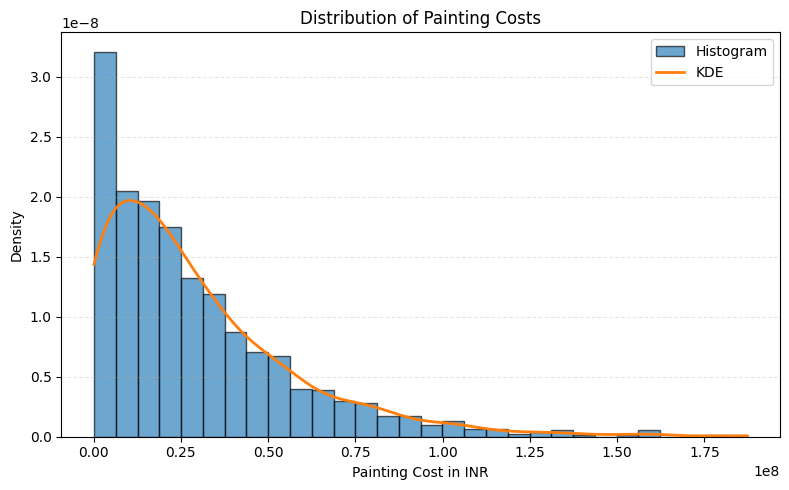


Figure saved to figures/target_distribution.png


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

df = pd.read_csv("painting_dataset_cleaned.csv")
df.columns = df.columns.str.strip()

df["sub_category"] = (
    df["sub_category"].astype("string").str.strip()
)

df = df[
    df["sub_category"].str.casefold() == "painting"
].copy()

df["amount_inr"] = pd.to_numeric(
    df["amount_inr"], errors="coerce"
)

costs = df["amount_inr"].to_numpy(dtype=float)
costs = costs[np.isfinite(costs) & (costs >= 0)]

if len(costs) == 0:
    raise ValueError("No valid painting cost values found.")

print("Number of samples:", len(costs))
print(f"Minimum cost: INR {costs.min():,.2f}")
print(f"Median cost: INR {np.median(costs):,.2f}")
print(f"Maximum cost: INR {costs.max():,.2f}")

costs = costs[costs > 0]

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    costs,
    bins=30,
    density=True,
    alpha=0.65,
    edgecolor="black",
    label="Histogram"
)

if len(costs) > 1 and np.std(costs) > 0:
    kde = gaussian_kde(costs)
    x_grid = np.linspace(costs.min(), costs.max(), 400)

    ax.plot(
        x_grid,
        kde(x_grid),
        linewidth=2,
        label="KDE"
    )

ax.set_title("Distribution of Painting Costs")
ax.set_xlabel("Painting Cost in INR")
ax.set_ylabel("Density")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFigure saved to figures/target_distribution.png")

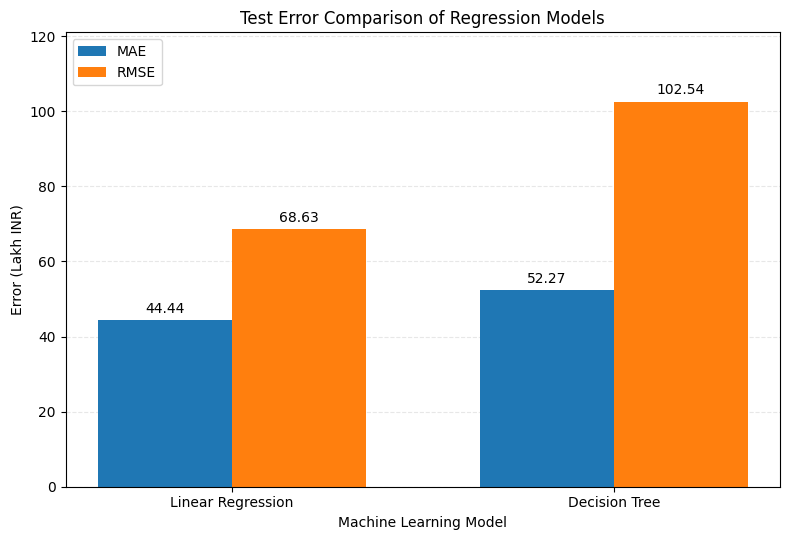

Figure saved to figures/test_error_comparison.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

models = [
    "Linear Regression",
    "Decision Tree"
]

mae_inr = [
    4443792.31,
    5227013.59
]

rmse_inr = [
    6862920.46,
    10253604.58
]

mae_lakh = np.array(mae_inr) / 100000
rmse_lakh = np.array(rmse_inr) / 100000

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5.5))

bars1 = ax.bar(
    x - width / 2,
    mae_lakh,
    width,
    label="MAE"
)

bars2 = ax.bar(
    x + width / 2,
    rmse_lakh,
    width,
    label="RMSE"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_title("Test Error Comparison of Regression Models")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Error (Lakh INR)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.set_ylim(0, max(rmse_lakh) * 1.18)

fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/test_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure saved to figures/test_error_comparison.png")

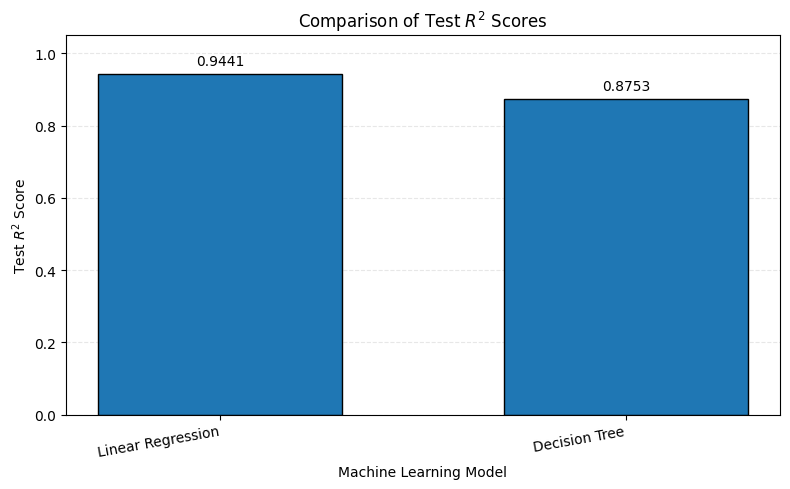

Figure saved to figures/test_r2_comparison.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import os

models = [
    "Linear Regression",
    "Decision Tree"
]

r2_scores = [
    0.9441,
    0.8753
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    models,
    r2_scores,
    width=0.6,
    edgecolor="black"
)

ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_title(r"Comparison of Test $R^2$ Scores")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel(r"Test $R^2$ Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=10, ha="right")
fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/test_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure saved to figures/test_r2_comparison.png")


TRAINING + TEST PREDICTION ENERGY
Linear Regression: 0.3547 J
Decision Tree: 0.2546 J


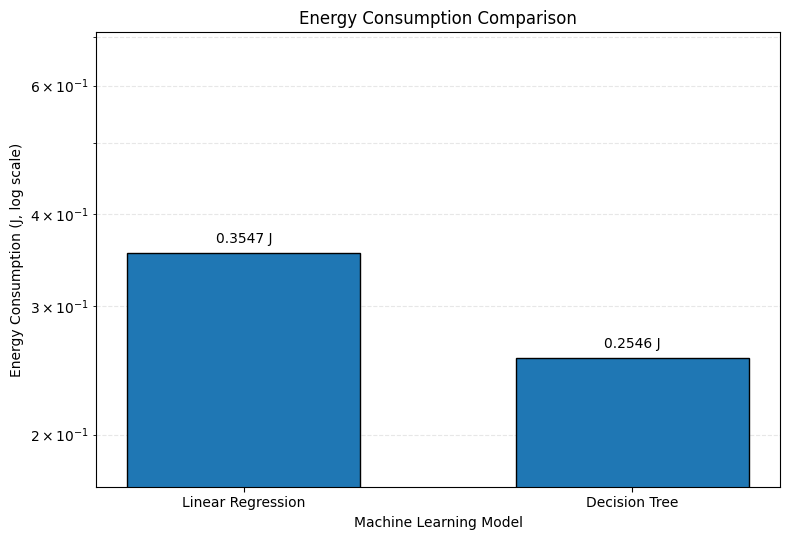


Figure saved to figures/energy_comparison.png


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

energy_files = {
    "Linear Regression": "linear_regression_energy_summary.csv",
    "Decision Tree": "decision_tree_energy_summary.csv"
}

energy_values = {}

for model_name, filename in energy_files.items():
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"Missing {filename}. Run the {model_name} "
            "energy measurement script first."
        )

    df = pd.read_csv(filename)

    if not {"Stage", "Energy_joules"}.issubset(df.columns):
        raise ValueError(
            f"{filename} must contain Stage and Energy_joules columns."
        )

    stages = df["Stage"].astype(str).str.lower()

    training_mask = (
        stages.str.contains("training", regex=False)
        & ~stages.str.contains("cross-validation", regex=False)
    )

    testing_mask = (
        stages.str.contains("test", regex=False)
        & stages.str.contains("prediction", regex=False)
    )

    selected = df[training_mask | testing_mask]

    if selected.empty:
        raise ValueError(
            f"No training/test prediction stages found in {filename}. "
            "Check the Stage column."
        )

    energy_values[model_name] = selected["Energy_joules"].sum()

print("\nTRAINING + TEST PREDICTION ENERGY")

for model_name, energy in energy_values.items():
    print(f"{model_name}: {energy:.4f} J")

models = list(energy_values.keys())
energies = [energy_values[m] for m in models]

if any(not np.isfinite(e) or e <= 0 for e in energies):
    raise ValueError(
        "All energy values must be positive and finite "
        "to use a logarithmic axis."
    )

fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.bar(
    models,
    energies,
    width=0.6,
    edgecolor="black"
)

ax.set_yscale("log")

ax.bar_label(
    bars,
    labels=[f"{e:.4f} J" for e in energies],
    padding=5
)

ax.set_title("Energy Consumption Comparison")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Energy Consumption (J, log scale)")
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
    which="both"
)
ax.set_axisbelow(True)
ax.set_ylim(min(energies) / 1.5, max(energies) * 2.0)

fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFigure saved to figures/energy_comparison.png")

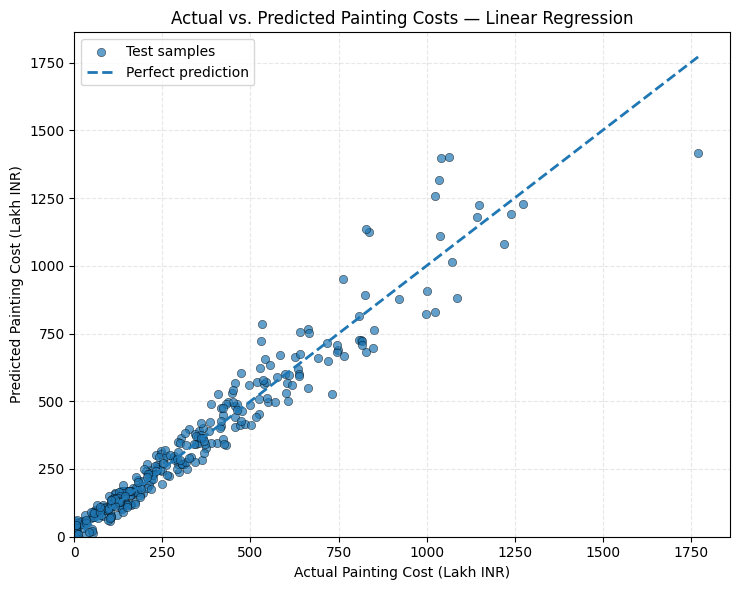

Figure saved to figures/linear_regression_actual_vs_predicted.png


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("linear_regression_test_predictions.csv")

actual = df["actual_amount_inr"].to_numpy()
predicted = df["predicted_amount_inr"].to_numpy()

valid = np.isfinite(actual) & np.isfinite(predicted)
actual = actual[valid]
predicted = predicted[valid]

if len(actual) == 0:
    raise ValueError("No valid actual-predicted pairs found.")

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.scatter(
    actual / 100000,
    predicted / 100000,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4,
    label="Test samples"
)

lower = min(actual.min(), predicted.min()) / 100000
upper = max(actual.max(), predicted.max()) / 100000

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

ax.set_title("Actual vs. Predicted Painting Costs — Linear Regression")
ax.set_xlabel("Actual Painting Cost (Lakh INR)")
ax.set_ylabel("Predicted Painting Cost (Lakh INR)")
ax.legend()
ax.grid(linestyle="--", alpha=0.3)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/linear_regression_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(
    "Figure saved to "
    "figures/linear_regression_actual_vs_predicted.png"
)

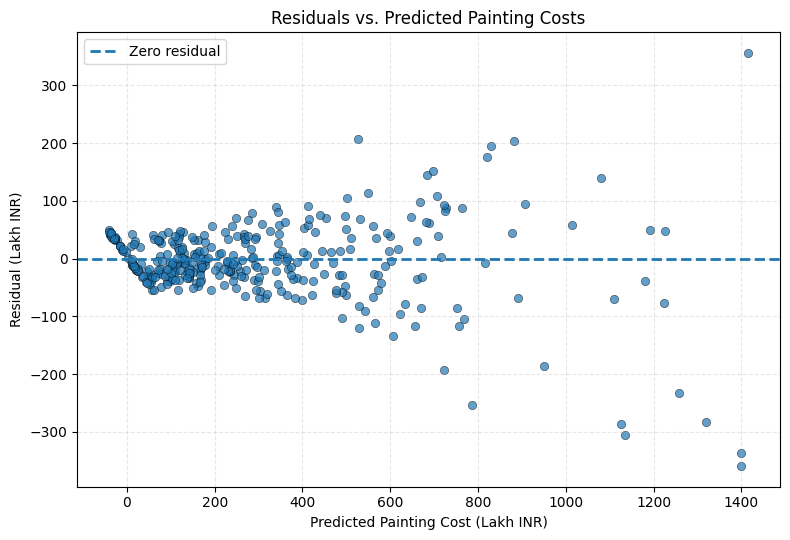

Figure saved to figures/linear_regression_residuals.png


In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("linear_regression_test_predictions.csv")

actual = df["actual_amount_inr"].to_numpy()
predicted = df["predicted_amount_inr"].to_numpy()
valid = np.isfinite(actual) & np.isfinite(predicted)
actual = actual[valid]
predicted = predicted[valid]

if len(actual) == 0:
    raise ValueError("No valid predictions found.")

residuals = actual - predicted
predicted_lakh = predicted / 100000
residuals_lakh = residuals / 100000

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    predicted_lakh,
    residuals_lakh,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=2,
    label="Zero residual"
)

ax.set_title("Residuals vs. Predicted Painting Costs")
ax.set_xlabel("Predicted Painting Cost (Lakh INR)")
ax.set_ylabel("Residual (Lakh INR)")

ax.legend()
ax.grid(linestyle="--", alpha=0.3)

fig.tight_layout()

os.makedirs("figures", exist_ok=True)

fig.savefig(
    "figures/linear_regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure saved to figures/linear_regression_residuals.png")